In [1]:
import tensorflow as tf
import numpy as np
import pandas as pd
import json
import os
import pickle
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# NO mixed precision — plain float32 only
print(f'TF Version   : {tf.__version__}')
print(f'Default dtype: {tf.keras.backend.floatx()}')  # must print float32
print(f'GPU Available: {tf.config.list_physical_devices("GPU")}')

SAVE_DIR = '/kaggle/working/nutrition_model'
os.makedirs(SAVE_DIR, exist_ok=True)
print(f'Save dir: {SAVE_DIR}')
print('✅ Setup done!')

2026-06-20 00:26:38.269270: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1781915198.447141      23 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1781915198.495464      23 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1781915198.903650      23 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1781915198.903693      23 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1781915198.903695      23 computation_placer.cc:177] computation placer alr

TF Version   : 2.19.0
Default dtype: float32
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Save dir: /kaggle/working/nutrition_model
✅ Setup done!


In [2]:
import os

print('All input files:')
for root, dirs, files in os.walk('/kaggle/input'):
    for f in files:
        print(os.path.join(root, f))

All input files:
/kaggle/input/datasets/barkataliarbab/usda-fooddata-central-foundation-foods-2025/FoodData_Central_foundation_food_csv_2025-04-24/food_update_log_entry.csv
/kaggle/input/datasets/barkataliarbab/usda-fooddata-central-foundation-foods-2025/FoodData_Central_foundation_food_csv_2025-04-24/input_food.csv
/kaggle/input/datasets/barkataliarbab/usda-fooddata-central-foundation-foods-2025/FoodData_Central_foundation_food_csv_2025-04-24/lab_method.csv
/kaggle/input/datasets/barkataliarbab/usda-fooddata-central-foundation-foods-2025/FoodData_Central_foundation_food_csv_2025-04-24/food_nutrient.csv
/kaggle/input/datasets/barkataliarbab/usda-fooddata-central-foundation-foods-2025/FoodData_Central_foundation_food_csv_2025-04-24/food_category.csv
/kaggle/input/datasets/barkataliarbab/usda-fooddata-central-foundation-foods-2025/FoodData_Central_foundation_food_csv_2025-04-24/nutrient.csv
/kaggle/input/datasets/barkataliarbab/usda-fooddata-central-foundation-foods-2025/FoodData_Central

In [3]:
import pandas as pd
import numpy as np
import os
import json

SAVE_DIR = '/kaggle/working/nutrition_model'
os.makedirs(SAVE_DIR, exist_ok=True)

# ── USDA Foundation Foods ─────────────────────────────────────
print('Reading USDA Foundation Foods...')
USDA_DIR = '/kaggle/input/datasets/barkataliarbab/usda-fooddata-central-foundation-foods-2025/FoodData_Central_foundation_food_csv_2025-04-24'

usda_df = pd.DataFrame()
try:
    food_df          = pd.read_csv(f'{USDA_DIR}/food.csv')
    nutrient_df      = pd.read_csv(f'{USDA_DIR}/nutrient.csv')
    food_nutrient_df = pd.read_csv(f'{USDA_DIR}/food_nutrient.csv')

    print(f'  food.csv      : {len(food_df)} rows')
    print(f'  nutrient.csv  : {len(nutrient_df)} rows')
    print(f'  food_nutrient : {len(food_nutrient_df)} rows')

    CALORIE_NAMES = ['Energy', 'Energy (Atwater General Factors)']
    PROTEIN_NAMES = ['Protein']
    CARB_NAMES    = ['Carbohydrate, by difference']
    FAT_NAMES     = ['Total lipid (fat)']
    FIBER_NAMES   = ['Fiber, total dietary']

    def get_ids(names):
        return nutrient_df[nutrient_df['name'].isin(names)]['id'].tolist()

    cal_ids   = get_ids(CALORIE_NAMES)
    pro_ids   = get_ids(PROTEIN_NAMES)
    carb_ids  = get_ids(CARB_NAMES)
    fat_ids   = get_ids(FAT_NAMES)
    fiber_ids = get_ids(FIBER_NAMES)

    print(f'  Calorie IDs: {cal_ids}')
    print(f'  Protein IDs: {pro_ids}')

    usda_rows = []
    for _, food_row in food_df.iterrows():
        fdc_id = food_row['fdc_id']
        name   = str(food_row.get('description', '')).lower().strip()
        if not name or len(name) < 2:
            continue

        fn = food_nutrient_df[food_nutrient_df['fdc_id'] == fdc_id]

        def get_val(ids):
            rows = fn[fn['nutrient_id'].isin(ids)]
            return float(rows['amount'].iloc[0]) if not rows.empty else 0.0

        cal   = get_val(cal_ids)
        pro   = get_val(pro_ids)
        carbs = get_val(carb_ids)
        fat   = get_val(fat_ids)
        fiber = get_val(fiber_ids)

        if cal and 10 < cal < 1500:
            usda_rows.append({
                'food_name': name,
                'calories' : round(cal,   1),
                'protein'  : round(pro,   1),
                'carbs'    : round(carbs, 1),
                'fat'      : round(fat,   1),
                'fiber'    : round(fiber, 1),
                'source'   : 'usda'
            })

    usda_df = pd.DataFrame(usda_rows)
    print(f'✅ USDA parsed: {len(usda_df):,} foods')

except Exception as e:
    print(f'⚠️ USDA error: {e}')
    usda_df = pd.DataFrame()

# ── Global Food & Nutrition Database ─────────────────────────
print('\nReading Global Food & Nutrition Database...')
GLOBAL_DIR = '/kaggle/input/datasets/ahsanneural/global-food-and-nutrition-database-2026'

global_rows = []

def parse_csv_auto(filepath):
    try:
        df = pd.read_csv(filepath)
        print(f'  {os.path.basename(filepath)}: {len(df)} rows | cols: {df.columns.tolist()}')
        col_map = {}
        for col in df.columns:
            c = col.lower()
            if ('name' in c or 'description' in c) and 'food' in c:
                col_map.setdefault('name', col)
            elif 'name' in c and 'food' not in c:
                col_map.setdefault('name', col)
            elif any(x in c for x in ['calor','energy','kcal']):
                col_map.setdefault('calories', col)
            elif 'protein' in c:
                col_map.setdefault('protein', col)
            elif 'carb' in c:
                col_map.setdefault('carbs', col)
            elif any(x in c for x in ['fat','lipid']) and 'saturated' not in c:
                col_map.setdefault('fat', col)
            elif any(x in c for x in ['fiber','fibre']):
                col_map.setdefault('fiber', col)
        return df, col_map
    except Exception as e:
        print(f'  ⚠️ Error: {e}')
        return None, {}

for fname in ['comprehensive_foods_usda.csv', 'healthy_foods_database.csv']:
    fpath = f'{GLOBAL_DIR}/{fname}'
    if not os.path.exists(fpath):
        continue
    df_g, col_map = parse_csv_auto(fpath)
    if df_g is None or 'name' not in col_map or 'calories' not in col_map:
        print(f'  ⚠️ Skipping {fname} — could not detect columns')
        continue
    print(f'  Detected columns: {col_map}')
    for _, row in df_g.iterrows():
        try:
            name = str(row[col_map['name']]).lower().strip()
            cal  = float(row.get(col_map.get('calories',''), 0) or 0)
            pro  = float(row.get(col_map.get('protein',''),  0) or 0)
            carb = float(row.get(col_map.get('carbs',''),    0) or 0)
            fat  = float(row.get(col_map.get('fat',''),      0) or 0)
            fib  = float(row.get(col_map.get('fiber',''),    0) or 0)
            if name and 10 < cal < 1500:
                global_rows.append({
                    'food_name': name, 'calories': round(cal,1),
                    'protein': round(pro,1), 'carbs': round(carb,1),
                    'fat': round(fat,1), 'fiber': round(fib,1),
                    'source': 'global_db'
                })
        except:
            pass

global_df = pd.DataFrame(global_rows)
print(f'✅ Global DB parsed: {len(global_df):,} foods')

# ── Custom foods (Egyptian + Arabic + all 108 classes) ────────
print('\nLoading custom foods...')
custom_foods = [
    # Egyptian/Arabic
    {'food_name': 'koshari',            'calories': 180, 'protein': 5,   'carbs': 35, 'fat': 3,   'fiber': 4,   'source': 'custom'},
    {'food_name': 'kunafa',             'calories': 380, 'protein': 8,   'carbs': 55, 'fat': 15,  'fiber': 1,   'source': 'custom'},
    {'food_name': 'fattah',             'calories': 280, 'protein': 12,  'carbs': 40, 'fat': 8,   'fiber': 2,   'source': 'custom'},
    {'food_name': 'molokhia',           'calories': 45,  'protein': 4,   'carbs': 8,  'fat': 0.5, 'fiber': 3,   'source': 'custom'},
    {'food_name': 'bamya',              'calories': 35,  'protein': 2,   'carbs': 7,  'fat': 0.2, 'fiber': 3.2, 'source': 'custom'},
    {'food_name': 'mansaf',             'calories': 450, 'protein': 28,  'carbs': 45, 'fat': 16,  'fiber': 2,   'source': 'custom'},
    {'food_name': 'kibbeh',             'calories': 290, 'protein': 18,  'carbs': 22, 'fat': 14,  'fiber': 2,   'source': 'custom'},
    {'food_name': 'shawarma',           'calories': 280, 'protein': 22,  'carbs': 25, 'fat': 10,  'fiber': 2,   'source': 'custom'},
    {'food_name': 'falafel',            'calories': 333, 'protein': 13,  'carbs': 32, 'fat': 18,  'fiber': 8,   'source': 'custom'},
    {'food_name': 'kebab',              'calories': 226, 'protein': 22,  'carbs': 4,  'fat': 14,  'fiber': 0,   'source': 'custom'},
    {'food_name': 'hummus',             'calories': 177, 'protein': 8,   'carbs': 20, 'fat': 8,   'fiber': 6,   'source': 'custom'},
    {'food_name': 'mahshi',             'calories': 180, 'protein': 6,   'carbs': 28, 'fat': 5,   'fiber': 3,   'source': 'custom'},
    {'food_name': 'muskhan',            'calories': 320, 'protein': 18,  'carbs': 30, 'fat': 14,  'fiber': 3,   'source': 'custom'},
    {'food_name': 'mojadra',            'calories': 220, 'protein': 9,   'carbs': 38, 'fat': 4,   'fiber': 8,   'source': 'custom'},
    {'food_name': 'mandi',              'calories': 400, 'protein': 25,  'carbs': 42, 'fat': 14,  'fiber': 2,   'source': 'custom'},
    {'food_name': 'fava beans',         'calories': 110, 'protein': 8,   'carbs': 18, 'fat': 0.5, 'fiber': 5,   'source': 'custom'},
    {'food_name': 'qatayef',            'calories': 280, 'protein': 6,   'carbs': 42, 'fat': 10,  'fiber': 1,   'source': 'custom'},
    {'food_name': 'shishabark',         'calories': 260, 'protein': 14,  'carbs': 28, 'fat': 10,  'fiber': 2,   'source': 'custom'},
    {'food_name': 'makmoura',           'calories': 290, 'protein': 15,  'carbs': 32, 'fat': 12,  'fiber': 3,   'source': 'custom'},
    {'food_name': 'samosa',             'calories': 262, 'protein': 5,   'carbs': 28, 'fat': 15,  'fiber': 2,   'source': 'custom'},
    {'food_name': 'rice with milk',     'calories': 150, 'protein': 4,   'carbs': 28, 'fat': 3,   'fiber': 0,   'source': 'custom'},
    {'food_name': 'plate of meat',      'calories': 320, 'protein': 28,  'carbs': 2,  'fat': 22,  'fiber': 0,   'source': 'custom'},
    {'food_name': 'pastries',           'calories': 400, 'protein': 6,   'carbs': 52, 'fat': 20,  'fiber': 1,   'source': 'custom'},
    {'food_name': 'ful medames',        'calories': 150, 'protein': 8,   'carbs': 22, 'fat': 2,   'fiber': 6,   'source': 'custom'},
    {'food_name': 'hawawshi',           'calories': 380, 'protein': 22,  'carbs': 28, 'fat': 18,  'fiber': 2,   'source': 'custom'},
    {'food_name': 'feteer',             'calories': 420, 'protein': 8,   'carbs': 58, 'fat': 18,  'fiber': 1,   'source': 'custom'},
    {'food_name': 'om ali',             'calories': 380, 'protein': 8,   'carbs': 48, 'fat': 18,  'fiber': 2,   'source': 'custom'},
    {'food_name': 'basbousa',           'calories': 380, 'protein': 6,   'carbs': 62, 'fat': 12,  'fiber': 1,   'source': 'custom'},
    {'food_name': 'kofta',              'calories': 250, 'protein': 20,  'carbs': 5,  'fat': 16,  'fiber': 0,   'source': 'custom'},
    {'food_name': 'macarona bechamel',  'calories': 320, 'protein': 14,  'carbs': 38, 'fat': 12,  'fiber': 2,   'source': 'custom'},
    # Food-101 classes
    {'food_name': 'apple pie',          'calories': 237, 'protein': 2,   'carbs': 34, 'fat': 11,  'fiber': 2,   'source': 'custom'},
    {'food_name': 'baklava',            'calories': 428, 'protein': 6,   'carbs': 56, 'fat': 21,  'fiber': 2,   'source': 'custom'},
    {'food_name': 'beef carpaccio',     'calories': 180, 'protein': 20,  'carbs': 2,  'fat': 10,  'fiber': 0,   'source': 'custom'},
    {'food_name': 'beef tartare',       'calories': 196, 'protein': 20,  'carbs': 3,  'fat': 12,  'fiber': 0,   'source': 'custom'},
    {'food_name': 'bread pudding',      'calories': 320, 'protein': 8,   'carbs': 48, 'fat': 11,  'fiber': 1,   'source': 'custom'},
    {'food_name': 'breakfast burrito',  'calories': 380, 'protein': 18,  'carbs': 42, 'fat': 16,  'fiber': 4,   'source': 'custom'},
    {'food_name': 'bruschetta',         'calories': 190, 'protein': 5,   'carbs': 28, 'fat': 7,   'fiber': 2,   'source': 'custom'},
    {'food_name': 'caesar salad',       'calories': 180, 'protein': 8,   'carbs': 10, 'fat': 13,  'fiber': 2,   'source': 'custom'},
    {'food_name': 'cannoli',            'calories': 297, 'protein': 7,   'carbs': 35, 'fat': 15,  'fiber': 1,   'source': 'custom'},
    {'food_name': 'caprese salad',      'calories': 160, 'protein': 9,   'carbs': 6,  'fat': 11,  'fiber': 1,   'source': 'custom'},
    {'food_name': 'carrot cake',        'calories': 415, 'protein': 5,   'carbs': 52, 'fat': 22,  'fiber': 2,   'source': 'custom'},
    {'food_name': 'cheesecake',         'calories': 321, 'protein': 6,   'carbs': 26, 'fat': 22,  'fiber': 0,   'source': 'custom'},
    {'food_name': 'cheese plate',       'calories': 350, 'protein': 20,  'carbs': 3,  'fat': 29,  'fiber': 0,   'source': 'custom'},
    {'food_name': 'chicken curry',      'calories': 240, 'protein': 22,  'carbs': 12, 'fat': 12,  'fiber': 2,   'source': 'custom'},
    {'food_name': 'chicken quesadilla', 'calories': 310, 'protein': 20,  'carbs': 28, 'fat': 13,  'fiber': 2,   'source': 'custom'},
    {'food_name': 'chicken wings',      'calories': 290, 'protein': 27,  'carbs': 0,  'fat': 19,  'fiber': 0,   'source': 'custom'},
    {'food_name': 'chocolate cake',     'calories': 371, 'protein': 5,   'carbs': 52, 'fat': 18,  'fiber': 3,   'source': 'custom'},
    {'food_name': 'chocolate mousse',   'calories': 220, 'protein': 5,   'carbs': 24, 'fat': 12,  'fiber': 2,   'source': 'custom'},
    {'food_name': 'churros',            'calories': 375, 'protein': 5,   'carbs': 45, 'fat': 20,  'fiber': 2,   'source': 'custom'},
    {'food_name': 'clam chowder',       'calories': 190, 'protein': 10,  'carbs': 18, 'fat': 8,   'fiber': 1,   'source': 'custom'},
    {'food_name': 'club sandwich',      'calories': 390, 'protein': 22,  'carbs': 38, 'fat': 16,  'fiber': 3,   'source': 'custom'},
    {'food_name': 'crab cakes',         'calories': 260, 'protein': 18,  'carbs': 18, 'fat': 12,  'fiber': 1,   'source': 'custom'},
    {'food_name': 'creme brulee',       'calories': 332, 'protein': 5,   'carbs': 35, 'fat': 19,  'fiber': 0,   'source': 'custom'},
    {'food_name': 'croque madame',      'calories': 450, 'protein': 24,  'carbs': 28, 'fat': 28,  'fiber': 2,   'source': 'custom'},
    {'food_name': 'cup cakes',          'calories': 380, 'protein': 4,   'carbs': 52, 'fat': 18,  'fiber': 1,   'source': 'custom'},
    {'food_name': 'deviled eggs',       'calories': 140, 'protein': 6,   'carbs': 1,  'fat': 12,  'fiber': 0,   'source': 'custom'},
    {'food_name': 'donuts',             'calories': 452, 'protein': 5,   'carbs': 51, 'fat': 25,  'fiber': 1,   'source': 'custom'},
    {'food_name': 'dumplings',          'calories': 280, 'protein': 12,  'carbs': 38, 'fat': 9,   'fiber': 2,   'source': 'custom'},
    {'food_name': 'filet mignon',       'calories': 271, 'protein': 26,  'carbs': 0,  'fat': 18,  'fiber': 0,   'source': 'custom'},
    {'food_name': 'fish and chips',     'calories': 430, 'protein': 20,  'carbs': 48, 'fat': 18,  'fiber': 3,   'source': 'custom'},
    {'food_name': 'foie gras',          'calories': 520, 'protein': 10,  'carbs': 5,  'fat': 50,  'fiber': 0,   'source': 'custom'},
    {'food_name': 'french fries',       'calories': 312, 'protein': 4,   'carbs': 41, 'fat': 15,  'fiber': 3,   'source': 'custom'},
    {'food_name': 'french onion soup',  'calories': 180, 'protein': 8,   'carbs': 18, 'fat': 8,   'fiber': 2,   'source': 'custom'},
    {'food_name': 'fried calamari',     'calories': 310, 'protein': 18,  'carbs': 28, 'fat': 14,  'fiber': 1,   'source': 'custom'},
    {'food_name': 'fried rice',         'calories': 238, 'protein': 7,   'carbs': 40, 'fat': 6,   'fiber': 1,   'source': 'custom'},
    {'food_name': 'frozen yogurt',      'calories': 159, 'protein': 4,   'carbs': 32, 'fat': 2,   'fiber': 0,   'source': 'custom'},
    {'food_name': 'garlic bread',       'calories': 290, 'protein': 7,   'carbs': 38, 'fat': 13,  'fiber': 2,   'source': 'custom'},
    {'food_name': 'gnocchi',            'calories': 250, 'protein': 6,   'carbs': 48, 'fat': 3,   'fiber': 2,   'source': 'custom'},
    {'food_name': 'greek salad',        'calories': 160, 'protein': 4,   'carbs': 10, 'fat': 12,  'fiber': 3,   'source': 'custom'},
    {'food_name': 'grilled cheese sandwich','calories': 380,'protein': 14,'carbs': 32,'fat': 22,  'fiber': 2,   'source': 'custom'},
    {'food_name': 'grilled salmon',     'calories': 234, 'protein': 30,  'carbs': 0,  'fat': 12,  'fiber': 0,   'source': 'custom'},
    {'food_name': 'guacamole',          'calories': 150, 'protein': 2,   'carbs': 8,  'fat': 13,  'fiber': 5,   'source': 'custom'},
    {'food_name': 'hamburger',          'calories': 295, 'protein': 17,  'carbs': 24, 'fat': 14,  'fiber': 1,   'source': 'custom'},
    {'food_name': 'hot dog',            'calories': 290, 'protein': 10,  'carbs': 24, 'fat': 17,  'fiber': 1,   'source': 'custom'},
    {'food_name': 'huevos rancheros',   'calories': 320, 'protein': 14,  'carbs': 28, 'fat': 16,  'fiber': 5,   'source': 'custom'},
    {'food_name': 'ice cream',          'calories': 207, 'protein': 4,   'carbs': 24, 'fat': 11,  'fiber': 0,   'source': 'custom'},
    {'food_name': 'lasagna',            'calories': 300, 'protein': 16,  'carbs': 30, 'fat': 12,  'fiber': 3,   'source': 'custom'},
    {'food_name': 'lobster bisque',     'calories': 280, 'protein': 14,  'carbs': 18, 'fat': 16,  'fiber': 1,   'source': 'custom'},
    {'food_name': 'lobster roll sandwich','calories': 390,'protein': 22, 'carbs': 38, 'fat': 16,  'fiber': 2,   'source': 'custom'},
    {'food_name': 'macaroni and cheese','calories': 350, 'protein': 12,  'carbs': 48, 'fat': 13,  'fiber': 2,   'source': 'custom'},
    {'food_name': 'macarons',           'calories': 420, 'protein': 5,   'carbs': 62, 'fat': 18,  'fiber': 1,   'source': 'custom'},
    {'food_name': 'miso soup',          'calories': 40,  'protein': 3,   'carbs': 5,  'fat': 1,   'fiber': 1,   'source': 'custom'},
    {'food_name': 'mussels',            'calories': 172, 'protein': 24,  'carbs': 7,  'fat': 5,   'fiber': 0,   'source': 'custom'},
    {'food_name': 'nachos',             'calories': 480, 'protein': 12,  'carbs': 55, 'fat': 26,  'fiber': 5,   'source': 'custom'},
    {'food_name': 'omelette',           'calories': 154, 'protein': 11,  'carbs': 1,  'fat': 12,  'fiber': 0,   'source': 'custom'},
    {'food_name': 'onion rings',        'calories': 411, 'protein': 5,   'carbs': 47, 'fat': 23,  'fiber': 3,   'source': 'custom'},
    {'food_name': 'oysters',            'calories': 81,  'protein': 9,   'carbs': 5,  'fat': 3,   'fiber': 0,   'source': 'custom'},
    {'food_name': 'paella',             'calories': 310, 'protein': 20,  'carbs': 38, 'fat': 8,   'fiber': 2,   'source': 'custom'},
    {'food_name': 'pancakes',           'calories': 227, 'protein': 6,   'carbs': 28, 'fat': 10,  'fiber': 1,   'source': 'custom'},
    {'food_name': 'panna cotta',        'calories': 280, 'protein': 5,   'carbs': 28, 'fat': 17,  'fiber': 0,   'source': 'custom'},
    {'food_name': 'pizza',              'calories': 266, 'protein': 11,  'carbs': 33, 'fat': 10,  'fiber': 2,   'source': 'custom'},
    {'food_name': 'prime rib',          'calories': 340, 'protein': 28,  'carbs': 0,  'fat': 25,  'fiber': 0,   'source': 'custom'},
    {'food_name': 'ramen',              'calories': 350, 'protein': 15,  'carbs': 48, 'fat': 11,  'fiber': 2,   'source': 'custom'},
    {'food_name': 'ravioli',            'calories': 280, 'protein': 12,  'carbs': 38, 'fat': 9,   'fiber': 2,   'source': 'custom'},
    {'food_name': 'red velvet cake',    'calories': 410, 'protein': 5,   'carbs': 52, 'fat': 21,  'fiber': 1,   'source': 'custom'},
    {'food_name': 'risotto',            'calories': 310, 'protein': 8,   'carbs': 48, 'fat': 10,  'fiber': 2,   'source': 'custom'},
    {'food_name': 'scallops',           'calories': 137, 'protein': 20,  'carbs': 6,  'fat': 3,   'fiber': 0,   'source': 'custom'},
    {'food_name': 'seaweed salad',      'calories': 70,  'protein': 2,   'carbs': 11, 'fat': 2,   'fiber': 3,   'source': 'custom'},
    {'food_name': 'shrimp and grits',   'calories': 380, 'protein': 22,  'carbs': 38, 'fat': 14,  'fiber': 2,   'source': 'custom'},
    {'food_name': 'spaghetti bolognese','calories': 320, 'protein': 16,  'carbs': 42, 'fat': 10,  'fiber': 4,   'source': 'custom'},
    {'food_name': 'spaghetti carbonara','calories': 380, 'protein': 18,  'carbs': 45, 'fat': 15,  'fiber': 2,   'source': 'custom'},
    {'food_name': 'spring rolls',       'calories': 220, 'protein': 6,   'carbs': 28, 'fat': 10,  'fiber': 2,   'source': 'custom'},
    {'food_name': 'steak',              'calories': 271, 'protein': 26,  'carbs': 0,  'fat': 18,  'fiber': 0,   'source': 'custom'},
    {'food_name': 'strawberry shortcake','calories': 310,'protein': 4,   'carbs': 45, 'fat': 13,  'fiber': 2,   'source': 'custom'},
    {'food_name': 'sushi',              'calories': 150, 'protein': 6,   'carbs': 28, 'fat': 1,   'fiber': 1,   'source': 'custom'},
    {'food_name': 'tacos',              'calories': 210, 'protein': 11,  'carbs': 20, 'fat': 9,   'fiber': 3,   'source': 'custom'},
    {'food_name': 'tiramisu',           'calories': 280, 'protein': 6,   'carbs': 32, 'fat': 15,  'fiber': 1,   'source': 'custom'},
    {'food_name': 'tuna tartare',       'calories': 150, 'protein': 20,  'carbs': 4,  'fat': 6,   'fiber': 0,   'source': 'custom'},
    {'food_name': 'waffles',            'calories': 291, 'protein': 8,   'carbs': 37, 'fat': 13,  'fiber': 1,   'source': 'custom'},
    {'food_name': 'gyoza',              'calories': 210, 'protein': 10,  'carbs': 24, 'fat': 8,   'fiber': 2,   'source': 'custom'},
    {'food_name': 'peking duck',        'calories': 340, 'protein': 22,  'carbs': 8,  'fat': 26,  'fiber': 0,   'source': 'custom'},
    {'food_name': 'pho',                'calories': 215, 'protein': 15,  'carbs': 30, 'fat': 4,   'fiber': 2,   'source': 'custom'},
    {'food_name': 'pad thai',           'calories': 357, 'protein': 14,  'carbs': 48, 'fat': 13,  'fiber': 3,   'source': 'custom'},
    {'food_name': 'bibimbap',           'calories': 490, 'protein': 18,  'carbs': 72, 'fat': 14,  'fiber': 5,   'source': 'custom'},
    {'food_name': 'edamame',            'calories': 122, 'protein': 11,  'carbs': 10, 'fat': 5,   'fiber': 5,   'source': 'custom'},
    {'food_name': 'takoyaki',           'calories': 260, 'protein': 10,  'carbs': 32, 'fat': 11,  'fiber': 1,   'source': 'custom'},
    {'food_name': 'escargots',          'calories': 130, 'protein': 18,  'carbs': 2,  'fat': 6,   'fiber': 0,   'source': 'custom'},
    {'food_name': 'ceviche',            'calories': 130, 'protein': 18,  'carbs': 8,  'fat': 3,   'fiber': 1,   'source': 'custom'},
    {'food_name': 'poutine',            'calories': 530, 'protein': 18,  'carbs': 56, 'fat': 28,  'fiber': 4,   'source': 'custom'},
    {'food_name': 'pulled pork sandwich','calories': 440,'protein': 28,  'carbs': 42, 'fat': 16,  'fiber': 2,   'source': 'custom'},
    {'food_name': 'pork chop',          'calories': 231, 'protein': 28,  'carbs': 0,  'fat': 13,  'fiber': 0,   'source': 'custom'},
    {'food_name': 'hot and sour soup',  'calories': 90,  'protein': 5,   'carbs': 12, 'fat': 3,   'fiber': 1,   'source': 'custom'},
    {'food_name': 'french toast',       'calories': 229, 'protein': 8,   'carbs': 28, 'fat': 9,   'fiber': 1,   'source': 'custom'},
    {'food_name': 'eggs benedict',      'calories': 358, 'protein': 18,  'carbs': 22, 'fat': 22,  'fiber': 1,   'source': 'custom'},
    {'food_name': 'beet salad',         'calories': 65,  'protein': 2,   'carbs': 13, 'fat': 1,   'fiber': 3,   'source': 'custom'},
    {'food_name': 'pierogi',            'calories': 260, 'protein': 7,   'carbs': 38, 'fat': 9,   'fiber': 2,   'source': 'custom'},
    # Fruits
    {'food_name': 'banana',             'calories': 89,  'protein': 1.1, 'carbs': 23, 'fat': 0.3, 'fiber': 2.6, 'source': 'custom'},
    {'food_name': 'avocado',            'calories': 160, 'protein': 2,   'carbs': 9,  'fat': 15,  'fiber': 7,   'source': 'custom'},
    {'food_name': 'orange',             'calories': 47,  'protein': 0.9, 'carbs': 12, 'fat': 0.1, 'fiber': 2.4, 'source': 'custom'},
    {'food_name': 'grapes',             'calories': 69,  'protein': 0.7, 'carbs': 18, 'fat': 0.2, 'fiber': 0.9, 'source': 'custom'},
    {'food_name': 'mango fruit',        'calories': 60,  'protein': 0.8, 'carbs': 15, 'fat': 0.4, 'fiber': 1.6, 'source': 'custom'},
    {'food_name': 'raspberry',          'calories': 52,  'protein': 1.2, 'carbs': 12, 'fat': 0.7, 'fiber': 6.5, 'source': 'custom'},
    {'food_name': 'cherry fruit',       'calories': 63,  'protein': 1.1, 'carbs': 16, 'fat': 0.2, 'fiber': 2.1, 'source': 'custom'},
    {'food_name': 'apple',              'calories': 52,  'protein': 0.3, 'carbs': 14, 'fat': 0.2, 'fiber': 2.4, 'source': 'custom'},
]

custom_df = pd.DataFrame(custom_foods)
print(f'✅ Custom foods: {len(custom_df)}')

# ── Merge all: priority = custom > global_db > usda ──────────
print('\nMerging all datasets...')
all_dfs = []
if not usda_df.empty:   all_dfs.append(usda_df)
if not global_df.empty: all_dfs.append(global_df)
all_dfs.append(custom_df)

combined = pd.concat(all_dfs, ignore_index=True)
combined['food_name'] = combined['food_name'].str.lower().str.strip()
combined = combined.drop_duplicates(subset=['food_name'], keep='last')
combined = combined.dropna(subset=['calories','protein','carbs','fat'])
combined['fiber'] = combined['fiber'].fillna(0)
combined = combined[(combined['calories'] > 0) & (combined['calories'] < 1500)]
combined = combined.reset_index(drop=True)

print(f'\n✅ Final Dataset Summary:')
print(f'  USDA Foundation Foods : {len(usda_df):,}')
print(f'  Global Food DB        : {len(global_df):,}')
print(f'  Custom (108 classes)  : {len(custom_df):,}')
print(f'  ─────────────────────────')
print(f'  Total after merge     : {len(combined):,}')

print('\n✅ Verifying key foods (custom values must win):')
for food in ['koshari','fattah','bamya','molokhia','pizza','hamburger','banana']:
    row = combined[combined['food_name'] == food]
    if not row.empty:
        r = row.iloc[0]
        print(f'  {food:<20}: cal={r["calories"]} src={r["source"]}')
    else:
        print(f'  ⚠️ {food}: NOT FOUND!')

combined.to_csv(f'{SAVE_DIR}/merged_dataset.csv', index=False)
print(f'\n✅ Merged dataset saved! ({len(combined):,} foods)')
df = combined

Reading USDA Foundation Foods...


/tmp/ipykernel_23/432049047.py:17: DtypeWarning: Columns (9) have mixed types. Specify dtype option on import or set low_memory=False.
  food_nutrient_df = pd.read_csv(f'{USDA_DIR}/food_nutrient.csv')


  food.csv      : 74175 rows
  nutrient.csv  : 477 rows
  food_nutrient : 155243 rows
  Calorie IDs: [2047, 1008, 1062]
  Protein IDs: [1003]
✅ USDA parsed: 340 foods

Reading Global Food & Nutrition Database...
  comprehensive_foods_usda.csv: 40000 rows | cols: ['fdc_id', 'food_name', 'data_type', 'food_category', 'brand_owner', 'brand_name', 'ingredients', 'serving_size', 'serving_unit', 'household_serving', 'calories', 'carbs_g', 'calcium_mg', 'fat_g', 'protein_g', 'saturated_fat_g', 'vitamin_c_mg', 'fiber_g', 'iron_mg', 'sodium_mg', 'sugar_g', 'cholesterol_mg', 'health_score', 'food_type']
  Detected columns: {'name': 'food_name', 'calories': 'calories', 'carbs': 'carbs_g', 'fat': 'fat_g', 'protein': 'protein_g', 'fiber': 'fiber_g'}
  healthy_foods_database.csv: 9028 rows | cols: ['food_name', 'food_type', 'calories', 'protein_g', 'fat_g', 'carbs_g', 'fiber_g', 'sugar_g', 'sodium_mg', 'health_score']
  Detected columns: {'name': 'food_name', 'calories': 'calories', 'protein': 'prot

In [4]:
import tensorflow as tf
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import json, os, pickle

SAVE_DIR = '/kaggle/working/nutrition_model'

X_text = df['food_name'].str.lower().str.replace('_', ' ').values
y = df[['calories','protein','carbs','fat','fiber']].values.astype(np.float32)

print(f'Training samples : {len(X_text):,}')
print(f'Output shape     : {y.shape}')

print('Vectorizing food names...')
vectorizer = TfidfVectorizer(
    analyzer='char_wb',
    ngram_range=(2, 4),
    max_features=3000,
    min_df=1
)
X = vectorizer.fit_transform(X_text).toarray().astype(np.float32)
print(f'Feature shape: {X.shape}')

scaler = StandardScaler()
y_scaled = scaler.fit_transform(y).astype(np.float32)

X_train, X_val, y_train, y_val = train_test_split(
    X, y_scaled, test_size=0.15, random_state=42
)
print(f'Train: {len(X_train):,} | Val: {len(X_val):,}')

with open(f'{SAVE_DIR}/vectorizer.pkl', 'wb') as f:
    pickle.dump(vectorizer, f)
with open(f'{SAVE_DIR}/scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)

# SAFE: Dense + ReLU only = TFLITE_BUILTINS, zero flex ops
print('\nBuilding model...')
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X.shape[1],), dtype=tf.float32),
    tf.keras.layers.Dense(512, activation='relu', dtype=tf.float32),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(256, activation='relu', dtype=tf.float32),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(128, activation='relu', dtype=tf.float32),
    tf.keras.layers.Dropout(0.1),
    tf.keras.layers.Dense(64,  activation='relu', dtype=tf.float32),
    tf.keras.layers.Dense(5,   dtype=tf.float32)
], name='nutriscan_nutrition_predictor')

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss='mse',
    metrics=['mae']
)
model.summary()

print('\nTraining...')
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=200,
    batch_size=32,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor='val_loss', patience=20,
            restore_best_weights=True, verbose=1
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss', factor=0.5,
            patience=10, verbose=1
        ),
        tf.keras.callbacks.ModelCheckpoint(
            f'{SAVE_DIR}/best_model.keras',
            monitor='val_loss', save_best_only=True, verbose=0
        )
    ],
    verbose=1
)

print(f'\n✅ Training complete!')
print(f'Best val MAE : {min(history.history["val_mae"]):.4f}')
print(f'Best val Loss: {min(history.history["val_loss"]):.4f}')

Training samples : 28,257
Output shape     : (28257, 5)
Vectorizing food names...
Feature shape: (28257, 3000)
Train: 24,018 | Val: 4,239

Building model...


I0000 00:00:1781915341.095047      23 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15511 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0


Model: "nutriscan_nutrition_predictor"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 512)            │     1,536,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,712,389 (6.53 MB)

 Trainable params: 1,710,853 (6.53 MB)

... (2 outputs left out)

I0000 00:00:1781915345.050467      65 service.cc:152] XLA service 0x159459c0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1781915345.050506      65 service.cc:160]   StreamExecutor device (0): Tesla P100-PCIE-16GB, Compute Capability 6.0
I0000 00:00:1781915345.498895      65 cuda_dnn.cc:529] Loaded cuDNN version 91002


 58/751 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 1.4991 - mae: 0.9039

I0000 00:00:1781915347.860188      65 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


751/751 ━━━━━━━━━━━━━━━━━━━━ 10s 8ms/step - loss: 0.6586 - mae: 0.5326 - val_loss: 0.5184 - val_mae: 0.4202 - learning_rate: 0.0010
Epoch 2/200
751/751 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.4728 - mae: 0.4220 - val_loss: 0.4718 - val_mae: 0.3775 - learning_rate: 0.0010
Epoch 3/200
751/751 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.4113 - mae: 0.3846 - val_loss: 0.5370 - val_mae: 0.3911 - learning_rate: 0.0010
Epoch 4/200
751/751 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.3766 - mae: 0.3642 - val_loss: 0.4469 - val_mae: 0.3510 - learning_rate: 0.0010
Epoch 5/200
751/751 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.3428 - mae: 0.3464 - val_loss: 0.4508 - val_mae: 0.3545 - learning_rate: 0.0010
Epoch 6/200
751/751 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.3222 - mae: 0.3360 - val_loss: 0.4344 - val_mae: 0.3477 - learning_rate: 0.0010
Epoch 7/200
751/751 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.3035 - mae: 0.3246 - val_loss: 0.4462 - val_mae: 0.3480 - learning_rate: 0.0010
Epoch 8/20

     FULL EVALUATION — NutriScan Nutrition Model

📊 1. PER-NUTRIENT METRICS

Nutrient          MAE     RMSE       R²    MAPE%
--------------------------------------------------
Calories        90.86   175.13    0.424    46.5%
Protein          2.57     5.43    0.723 198392096.0%
Carbs            7.78    13.56    0.777 72573808.0%
Fat              4.24     8.26    0.744   100.2%
Fiber            1.44     3.83    0.359    57.6%

📊 2. OVERALL METRICS

  Overall MAE  : 21.378
  Overall RMSE : 78.698
  Overall R²   : 0.605
  Total params : 1,712,389
  Train samples: 24,018
  Val samples  : 4,239

📊 3. TRAIN vs VALIDATION

Nutrient      Train MAE    Val MAE      Gap
---------------------------------------------
Calories          49.92      90.86   40.94 ⚠️
Protein            1.69       2.57    0.88 ✅
Carbs              4.60       7.78    3.18 ✅
Fat                2.59       4.24    1.65 ✅
Fiber              0.88       1.44    0.56 ✅

📊 4. ACCURACY WITHIN TOLERANCE

Nutrient      ±5%  ±10%  ±2

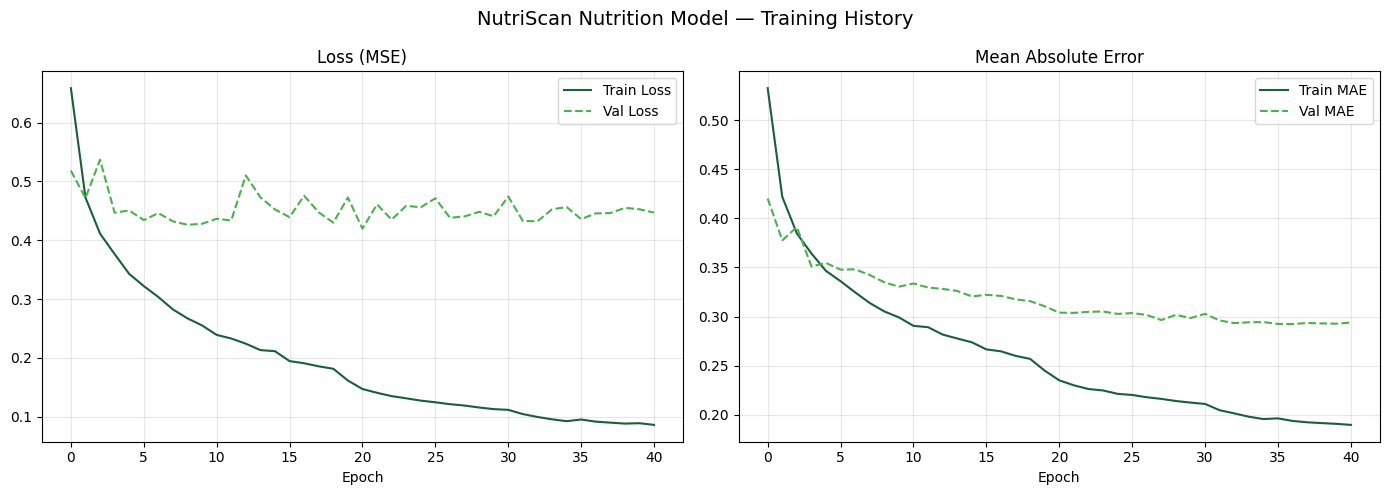

✅ Training curves saved!


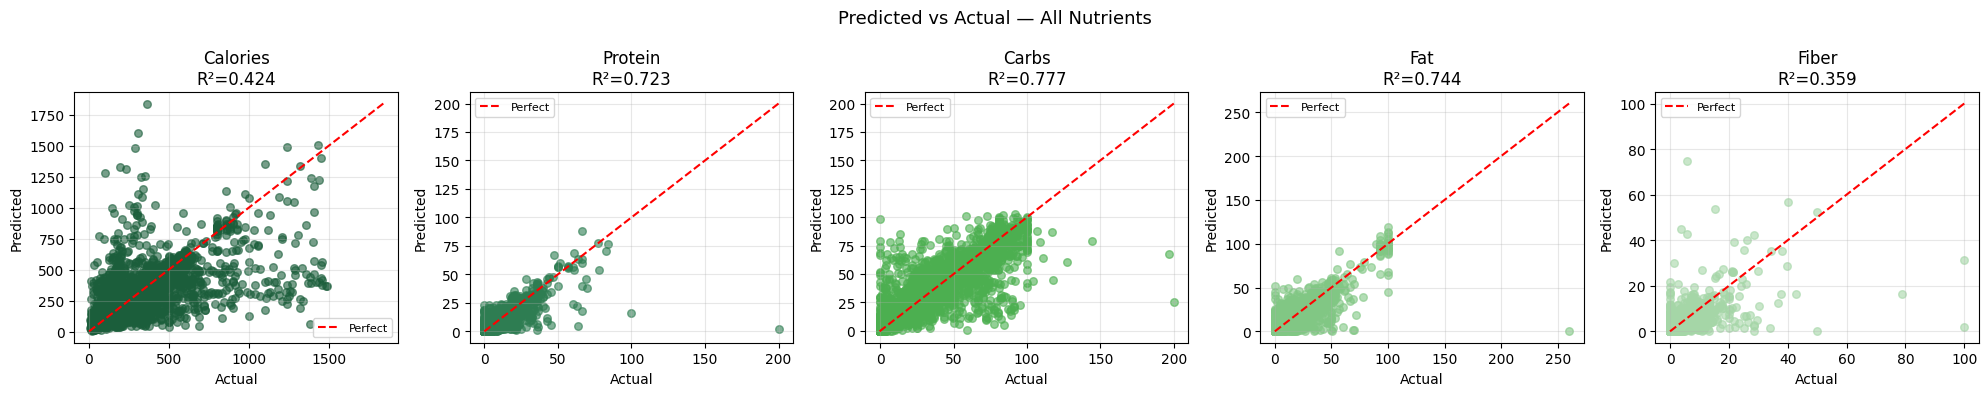

✅ Scatter plots saved!


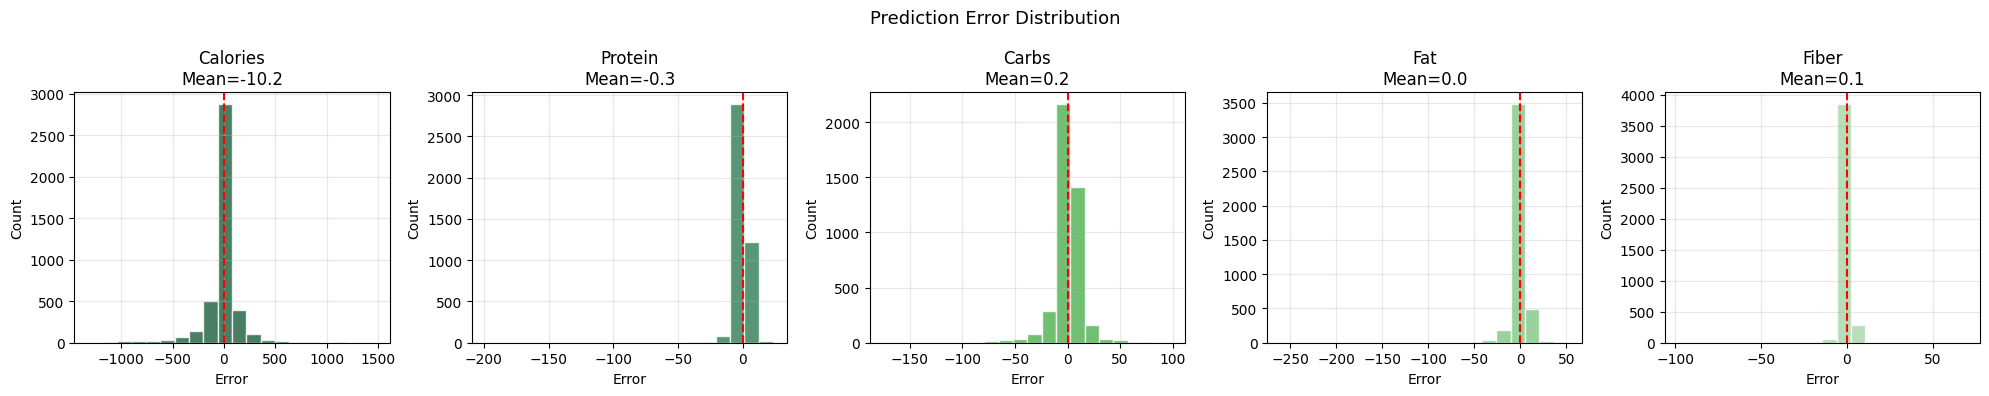

✅ Error distribution saved!

Converting to TFLite...


AttributeError: 'int' object has no attribute 'lite'

In [5]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import json, os

SAVE_DIR = '/kaggle/working/nutrition_model'
nutrients = ['Calories', 'Protein', 'Carbs', 'Fat', 'Fiber']
colors    = ['#1B5E3B', '#2E7D52', '#4CAF50', '#81C784', '#A5D6A7']

# Predictions
y_pred_s = model.predict(X_val,   verbose=0)
y_pred   = np.clip(scaler.inverse_transform(y_pred_s), 0, None)
y_true   = scaler.inverse_transform(y_val)
y_tr_s   = model.predict(X_train, verbose=0)
y_tr_p   = np.clip(scaler.inverse_transform(y_tr_s), 0, None)
y_tr_t   = scaler.inverse_transform(y_train)

print('=' * 65)
print('     FULL EVALUATION — NutriScan Nutrition Model')
print('=' * 65)

# 1. Per-nutrient metrics
print('\n📊 1. PER-NUTRIENT METRICS\n')
print(f'{"Nutrient":<12} {"MAE":>8} {"RMSE":>8} {"R²":>8} {"MAPE%":>8}')
print('-' * 50)
all_metrics = {}
for i, n in enumerate(nutrients):
    mae  = mean_absolute_error(y_true[:,i], y_pred[:,i])
    rmse = np.sqrt(mean_squared_error(y_true[:,i], y_pred[:,i]))
    r2   = r2_score(y_true[:,i], y_pred[:,i])
    mask = y_true[:,i] > 0
    mape = np.mean(np.abs((y_true[mask,i]-y_pred[mask,i])/y_true[mask,i]))*100
    print(f'{n:<12} {mae:>8.2f} {rmse:>8.2f} {r2:>8.3f} {mape:>7.1f}%')
    all_metrics[n] = {'MAE':round(mae,2),'RMSE':round(rmse,2),
                      'R2':round(r2,3),'MAPE':round(mape,1)}

# 2. Overall
print('\n📊 2. OVERALL METRICS\n')
overall_mae  = mean_absolute_error(y_true, y_pred)
overall_rmse = np.sqrt(mean_squared_error(y_true, y_pred))
overall_r2   = np.mean([r2_score(y_true[:,i],y_pred[:,i]) for i in range(5)])
print(f'  Overall MAE  : {overall_mae:.3f}')
print(f'  Overall RMSE : {overall_rmse:.3f}')
print(f'  Overall R²   : {overall_r2:.3f}')
print(f'  Total params : {model.count_params():,}')
print(f'  Train samples: {len(X_train):,}')
print(f'  Val samples  : {len(X_val):,}')

# 3. Overfitting check
print('\n📊 3. TRAIN vs VALIDATION\n')
print(f'{"Nutrient":<12} {"Train MAE":>10} {"Val MAE":>10} {"Gap":>8}')
print('-' * 45)
for i, n in enumerate(nutrients):
    tr  = mean_absolute_error(y_tr_t[:,i], y_tr_p[:,i])
    val = mean_absolute_error(y_true[:,i], y_pred[:,i])
    gap = val - tr
    print(f'{n:<12} {tr:>10.2f} {val:>10.2f} {gap:>7.2f} {"✅" if gap<15 else "⚠️"}')

# 4. Tolerance accuracy
print('\n📊 4. ACCURACY WITHIN TOLERANCE\n')
tolerances = [5, 10, 20, 30]
print(f'{"Nutrient":<12}', end='')
for t in tolerances: print(f'  ±{t}%', end='')
print()
print('-' * 55)
for i, n in enumerate(nutrients):
    print(f'{n:<12}', end='')
    for t in tolerances:
        mask   = y_true[:,i] > 0
        within = np.mean(np.abs(y_pred[mask,i]-y_true[mask,i])/y_true[mask,i] < t/100)*100
        print(f'  {within:>4.1f}%', end='')
    print()

# 5. Known food predictions
print('\n📊 5. PREDICTIONS ON KNOWN FOODS\n')
test_cases = [
    ('koshari',        180, 5,   35, 3,   4),
    ('fattah',         280, 12,  40, 8,   2),
    ('bamya',          35,  2,   7,  0.2, 3.2),
    ('molokhia',       45,  4,   8,  0.5, 3),
    ('kunafa',         380, 8,   55, 15,  1),
    ('pizza',          266, 11,  33, 10,  2),
    ('hamburger',      295, 17,  24, 14,  1),
    ('banana',         89,  1.1, 23, 0.3, 2.6),
    ('grilled salmon', 234, 30,  0,  12,  0),
    ('steak',          271, 26,  0,  18,  0),
    ('chicken curry',  240, 22,  12, 12,  2),
    ('french fries',   312, 4,   41, 15,  3),
]
print(f'{"Food":<22} {"":>4} {"Cal":>6} {"Pro":>6} {"Carb":>6} {"Fat":>6} {"Fib":>6}')
print('-' * 62)
for food, tc, tp, tcarb, tf, tfib in test_cases:
    vec  = vectorizer.transform([food.lower()]).toarray().astype(np.float32)
    pred = np.clip(scaler.inverse_transform(model.predict(vec,verbose=0))[0],0,None)
    print(f'{food:<22} {"True":>4} {tc:>6.1f} {tp:>6.1f} {tcarb:>6.1f} {tf:>6.1f} {tfib:>6.1f}')
    print(f'{"":22} {"Pred":>4} {pred[0]:>6.1f} {pred[1]:>6.1f} {pred[2]:>6.1f} {pred[3]:>6.1f} {pred[4]:>6.1f}')
    err = abs(pred[0]-tc)/tc*100 if tc>0 else 0
    print(f'{"":22} {"Err%":>4} {err:>5.1f}%')
    print()

# 6. Training curves
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('NutriScan Nutrition Model — Training History', fontsize=14)
axes[0].plot(history.history['loss'],     label='Train Loss', color='#1B5E3B')
axes[0].plot(history.history['val_loss'], label='Val Loss',   color='#4CAF50', linestyle='--')
axes[0].set_title('Loss (MSE)'); axes[0].set_xlabel('Epoch'); axes[0].legend(); axes[0].grid(True, alpha=0.3)
axes[1].plot(history.history['mae'],     label='Train MAE', color='#1B5E3B')
axes[1].plot(history.history['val_mae'], label='Val MAE',   color='#4CAF50', linestyle='--')
axes[1].set_title('Mean Absolute Error'); axes[1].set_xlabel('Epoch'); axes[1].legend(); axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(f'{SAVE_DIR}/training_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Training curves saved!')

# 7. Predicted vs Actual
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
fig.suptitle('Predicted vs Actual — All Nutrients', fontsize=13)
for i, (n, ax, c) in enumerate(zip(nutrients, axes, colors)):
    ax.scatter(y_true[:,i], y_pred[:,i], alpha=0.6, color=c, s=30)
    mn = min(y_true[:,i].min(), y_pred[:,i].min())
    mx = max(y_true[:,i].max(), y_pred[:,i].max())
    ax.plot([mn,mx],[mn,mx],'r--',linewidth=1.5,label='Perfect')
    ax.set_title(f'{n}\nR²={r2_score(y_true[:,i],y_pred[:,i]):.3f}')
    ax.set_xlabel('Actual'); ax.set_ylabel('Predicted')
    ax.legend(fontsize=8); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(f'{SAVE_DIR}/predicted_vs_actual.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Scatter plots saved!')

# 8. Error distribution
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
fig.suptitle('Prediction Error Distribution', fontsize=13)
for i, (n, ax, c) in enumerate(zip(nutrients, axes, colors)):
    errors = y_pred[:,i] - y_true[:,i]
    ax.hist(errors, bins=20, color=c, edgecolor='white', alpha=0.8)
    ax.axvline(0, color='red', linestyle='--', linewidth=1.5)
    ax.set_title(f'{n}\nMean={errors.mean():.1f}')
    ax.set_xlabel('Error'); ax.set_ylabel('Count'); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(f'{SAVE_DIR}/error_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Error distribution saved!')

# 9. Convert to TFLite
print('\nConverting to TFLite...')
converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS]
converter.target_spec.supported_types = [tf.float32]
tflite_model = converter.convert()

with open(f'{SAVE_DIR}/nutrition_model.tflite', 'wb') as f:
    f.write(tflite_model)
print(f'✅ TFLite saved! Size: {len(tflite_model)/1024:.1f} KB')

interp = tf.lite.Interpreter(model_path=f'{SAVE_DIR}/nutrition_model.tflite')
interp.allocate_tensors()
print(f'Input : {interp.get_input_details()[0]["shape"]}')
print(f'Output: {interp.get_output_details()[0]["shape"]}')
print('✅ TFLite verified!')

# 10. Save vectorizer + scaler as JSON
vocab = {str(k): int(v) for k, v in vectorizer.vocabulary_.items()}
idf   = [float(x) for x in vectorizer.idf_]
feat  = [str(x) for x in vectorizer.get_feature_names_out()]
with open(f'{SAVE_DIR}/vectorizer.json', 'w', encoding='utf-8') as f:
    json.dump({'vocabulary':vocab,'idf':idf,'feature_names':feat,
               'ngram_range':[2,4],'max_features':3000}, f, ensure_ascii=False)
print('✅ vectorizer.json saved!')

with open(f'{SAVE_DIR}/scaler.json', 'w') as f:
    json.dump({'mean':[float(x) for x in scaler.mean_],
               'scale':[float(x) for x in scaler.scale_],
               'nutrients':['calories','protein','carbs','fat','fiber']}, f)
print('✅ scaler.json saved!')

# 11. Evaluation report
eval_report = {
    'model_name': 'NutriScan Nutrition Prediction Model',
    'training_data': {
        'usda_foods'   : len(usda_df),
        'global_db'    : len(global_df),
        'custom_foods' : len(custom_df),
        'total'        : len(combined),
        'train_samples': len(X_train),
        'val_samples'  : len(X_val),
    },
    'overall': {
        'MAE' : round(overall_mae,  3),
        'RMSE': round(overall_rmse, 3),
        'R2'  : round(overall_r2,   3),
        'total_params': model.count_params(),
    },
    'per_nutrient': all_metrics,
    'tflite_size_kb': round(len(tflite_model)/1024, 1),
}
with open(f'{SAVE_DIR}/evaluation_report.json', 'w') as f:
    json.dump(eval_report, f, indent=2)
print('✅ evaluation_report.json saved!')

# Final summary
print('\n' + '='*65)
print('✅ ALL DONE!')
print('='*65)
print('\n📁 Output files:')
for fname in sorted(os.listdir(SAVE_DIR)):
    fpath = f'{SAVE_DIR}/{fname}'
    if os.path.isfile(fpath):
        size = os.path.getsize(fpath)/1024
        unit = 'KB' if size < 1024 else 'MB'
        size = size if size < 1024 else size/1024
        print(f'  {fname:<35}: {size:.1f} {unit}')
print('\n⚠️  Click Save Version now!')
print('📥 Download: nutrition_model.tflite, vectorizer.json, scaler.json, evaluation_report.json')

In [ ]:
import json, os
import numpy as np

SAVE_DIR = '/kaggle/working/nutrition_model'

# Save evaluation report — all values converted to Python native types
eval_report = {
    'model_name': 'NutriScan Nutrition Prediction Model',
    'training_data': {
        'usda_foods'   : int(len(usda_df)),
        'global_db'    : int(len(global_df)),
        'custom_foods' : int(len(custom_df)),
        'total'        : int(len(combined)),
        'train_samples': int(len(X_train)),
        'val_samples'  : int(len(X_val)),
    },
    'overall': {
        'MAE' : float(overall_mae),
        'RMSE': float(overall_rmse),
        'R2'  : float(overall_r2),
        'total_params': int(model.count_params()),
    },
    'per_nutrient': {
        k: {kk: float(vv) for kk, vv in v.items()}
        for k, v in all_metrics.items()
    },
    'tflite_size_kb': float(len(tflite_model)/1024),
}

with open(f'{SAVE_DIR}/evaluation_report.json', 'w') as f:
    json.dump(eval_report, f, indent=2)
print('✅ evaluation_report.json saved!')

print('\n📁 Output files:')
for fname in sorted(os.listdir(SAVE_DIR)):
    fpath = f'{SAVE_DIR}/{fname}'
    if os.path.isfile(fpath):
        size = os.path.getsize(fpath)/1024
        unit = 'KB' if size < 1024 else 'MB'
        size = size if size < 1024 else size/1024
        print(f'  {fname:<35}: {size:.1f} {unit}')

print('\n⚠️ Click Save Version now!')
print('📥 Download: nutrition_model.tflite, vectorizer.json, scaler.json, evaluation_report.json')

In [ ]:
from google.colab import files  # this is Kaggle not colab but try anyway

# Alternative: zip all files and download at once
import zipfile
import os

SAVE_DIR = '/kaggle/working/nutrition_model'
zip_path = '/kaggle/working/nutrition_files.zip'

with zipfile.ZipFile(zip_path, 'w') as zipf:
    for fname in ['nutrition_model.tflite', 'vectorizer.json', 
                  'scaler.json', 'evaluation_report.json']:
        fpath = f'{SAVE_DIR}/{fname}'
        if os.path.exists(fpath):
            zipf.write(fpath, fname)
            print(f'✅ Added: {fname}')
        else:
            print(f'❌ Missing: {fname}')

size = os.path.getsize(zip_path) / (1024*1024)
print(f'\n✅ ZIP created! Size: {size:.1f} MB')
print(f'Path: {zip_path}')